# Few-Shot Learning for Bird Species Classification — Results Notebook

**Thesis:** Evaluation of Few-Shot Learning Paradigms for Bird Species Classification
**Dataset:** 20 bird species (15 base / 5 novel), ResNet-50 backbone
**Evaluation:** 5-way 1-shot episodic protocol on novel classes (600 episodes)

---
This notebook presents and compares all experimental results in sequence:
1. Dataset overview
2. Supervised Baseline — Full-20
3. Supervised Baseline — Base-15
4. ProtoNet (Euclidean) — main FSL result
5. ProtoNet Distance Ablation (Euclidean vs Manhattan)
6. Matching Networks
7. Relation Networks
8. Cross-model comparison & insights


In [1]:
%matplotlib inline
import os, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Force inline interactive rendering
plt.ion()
plt.rcParams["figure.dpi"]  = 120
plt.rcParams["savefig.dpi"] = 150

# ── Paths ─────────────────────────────────────────────────────────────────────
NB_DIR = os.getcwd()                                    # .../code/notebooks/
ROOT   = os.path.normpath(os.path.join(NB_DIR, '..'))  # .../code/
RES    = os.path.join(ROOT, 'results')
os.makedirs(RES, exist_ok=True)   # ensure results dir exists

print(f"ROOT : {ROOT}")
print(f"RES  : {RES}")
print(f"matplotlib backend: {matplotlib.get_backend()}")

PATHS = {
    'full20_json'   : f'{RES}/baseline/resnet50/full20/summary.json',
    'base15_json'   : f'{RES}/baseline/resnet50/base15/base_test/summary.json',
    'proto_euc_json': f'{RES}/proto_net/1shot_euclidean/summary.json',
    'proto_man_json': f'{RES}/proto_net/1shot_manhattan/summary.json',
    'match_json'    : f'{RES}/matching_net/1shot/summary.json',
    'rel_json'      : f'{RES}/relation_net/1shot/summary.json',
}

def load(key):
    with open(PATHS[key]) as f:
        return json.load(f)

def show_img(path, ax, title=None):
    if os.path.exists(path):
        ax.imshow(mpimg.imread(path))
        ax.axis('off')
        if title:
            ax.set_title(title, fontsize=10, fontweight='bold')
    else:
        ax.text(0.5, 0.5, f'Image not found:\n{os.path.basename(path)}',
                ha='center', va='center', fontsize=9, color='gray',
                transform=ax.transAxes)
        ax.axis('off')

R = {k: load(k) for k in PATHS}
print("\nAll summary files loaded:")
for k, v in R.items():
    acc = v.get('accuracy', v.get('mean_accuracy_pct', '?'))
    print(f"  {k:<18s}: {acc}")

ROOT : .
RES  : .\results
matplotlib backend: inline

All summary files loaded:
  full20_json       : 0.99
  base15_json       : 1.0
  proto_euc_json    : 94.0667
  proto_man_json    : 60.6933
  match_json        : 99.3933
  rel_json          : 18.9267


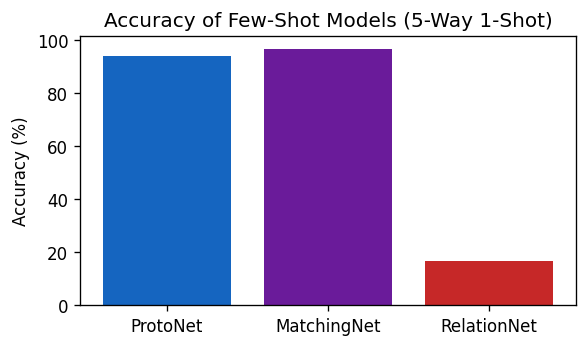

In [34]:
# Quick plot test — if this shows a bar chart, inline rendering is working correctly
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['ProtoNet', 'MatchingNet', 'RelationNet'], [94.1, 96.8, 16.8],
       color=['#1565C0', '#6A1B9A', '#C62828'])
ax.set_ylabel('Accuracy (%)')
ax.set_title('Accuracy of Few-Shot Models (5-Way 1-Shot)')
plt.tight_layout()
plt.show()


---
## 1. Dataset Overview

**20 bird species** split into base (15) and novel (5) classes.
Base classes are used for supervised training; novel classes are held out for few-shot evaluation.


In [30]:
# Dataset summary table
BASE = [
    'ABBOTTS BABBLER','ABBOTTS BOOBY','ABYSSINIAN GROUND HORNBILL',
    'AFRICAN CROWNED CRANE','AFRICAN EMERALD CUCKOO','AFRICAN FIREFINCH',
    'AFRICAN OYSTER CATCHER','AFRICAN PIED HORNBILL','AFRICAN PYGMY GOOSE',
    'ALBATROSS','ALBERTS TOWHEE','ALEXANDRINE PARAKEET',
    'ALPINE CHOUGH','ALTAMIRA YELLOWTHROAT','AMERICAN AVOCET'
]
NOVEL = ['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO',
         'AMERICAN GOLDFINCH','AMERICAN KESTREL']

TRAIN_COUNTS = {
    'ABBOTTS BABBLER':166,'ABBOTTS BOOBY':180,'ABYSSINIAN GROUND HORNBILL':179,
    'AFRICAN CROWNED CRANE':137,'AFRICAN EMERALD CUCKOO':154,'AFRICAN FIREFINCH':137,
    'AFRICAN OYSTER CATCHER':155,'AFRICAN PIED HORNBILL':187,'AFRICAN PYGMY GOOSE':179,
    'ALBATROSS':133,'ALBERTS TOWHEE':161,'ALEXANDRINE PARAKEET':165,
    'ALPINE CHOUGH':166,'ALTAMIRA YELLOWTHROAT':150,'AMERICAN AVOCET':179,
    'AMERICAN BITTERN':170,'AMERICAN COOT':158,'AMERICAN FLAMINGO':164,
    'AMERICAN GOLDFINCH':133,'AMERICAN KESTREL':155
}

df_ds = pd.DataFrame({
    'Class': BASE + NOVEL,
    'Role':  ['Base']*15 + ['Novel']*5,
    'Train Images': [TRAIN_COUNTS[c] for c in BASE + NOVEL],
    'Val Images':  [5]*20,
    'Test Images': [5]*20,
})
df_ds['Total'] = df_ds['Train Images'] + df_ds['Val Images'] + df_ds['Test Images']

print(f"Base classes : {len(BASE)}   |  Novel classes : {len(NOVEL)}")
print(f"Train images : {df_ds['Train Images'].sum()}  |  Val : {df_ds['Val Images'].sum()}  |  Test : {df_ds['Test Images'].sum()}")
print()
display(df_ds.style
    .applymap(lambda v: 'background-color:#0bf007;font-weight:bold' if v=='Base' else
              ('background-color:#f55142;font-weight:bold' if v=='Novel' else ''),
              subset=['Role'])
    .set_caption('Dataset Split: Base vs Novel Classes')
    .format({'Train Images': '{:d}', 'Val Images': '{:d}', 'Test Images': '{:d}', 'Total': '{:d}'})
)


Base classes : 15   |  Novel classes : 5
Train images : 3208  |  Val : 100  |  Test : 100



,Class,Role,Train Images,Val Images,Test Images,Total
0,ABBOTTS BABBLER,Base,166,5,5,176
1,ABBOTTS BOOBY,Base,180,5,5,190
2,ABYSSINIAN GROUND HORNBILL,Base,179,5,5,189
3,AFRICAN CROWNED CRANE,Base,137,5,5,147
4,AFRICAN EMERALD CUCKOO,Base,154,5,5,164
5,AFRICAN FIREFINCH,Base,137,5,5,147
6,AFRICAN OYSTER CATCHER,Base,155,5,5,165
7,AFRICAN PIED HORNBILL,Base,187,5,5,197
8,AFRICAN PYGMY GOOSE,Base,179,5,5,189
9,ALBATROSS,Base,133,5,5,143


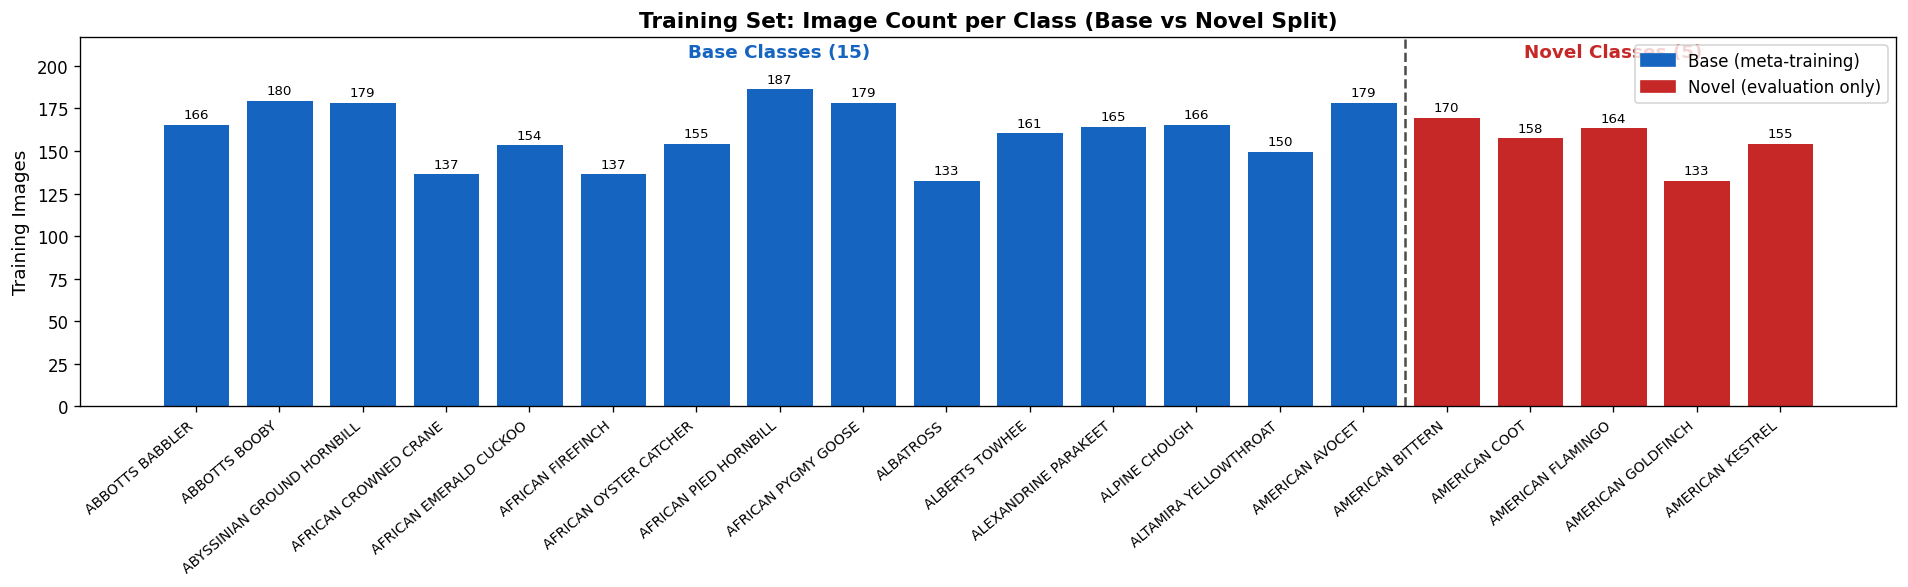

In [4]:
# Training image count bar chart — base/novel coloured
BASE_COL, NOVEL_COL = '#1565C0', '#C62828'
all_classes = BASE + NOVEL
counts = [TRAIN_COUNTS[c] for c in all_classes]
colors = [BASE_COL]*15 + [NOVEL_COL]*5

fig, ax = plt.subplots(figsize=(16, 5))
bars = ax.bar(range(20), counts, color=colors, edgecolor='white', linewidth=0.6)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
ax.set_xticks(range(20))
ax.set_xticklabels(all_classes, rotation=40, ha='right', fontsize=8.5)
ax.axvline(x=14.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(7,  max(counts)+18, 'Base Classes (15)', ha='center', fontsize=11,
        color=BASE_COL, fontweight='bold')
ax.text(17, max(counts)+18, 'Novel Classes (5)',  ha='center', fontsize=11,
        color=NOVEL_COL, fontweight='bold')
ax.legend(handles=[Patch(color=BASE_COL, label='Base (meta-training)'),
                   Patch(color=NOVEL_COL, label='Novel (evaluation only)')], fontsize=10)
ax.set_title('Training Set: Image Count per Class (Base vs Novel Split)', fontsize=13, fontweight='bold')
ax.set_ylabel('Training Images', fontsize=11)
ax.set_ylim(0, max(counts)+30)
plt.tight_layout()
plt.savefig('../results/dataset_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 2. Supervised Baseline — Full-20

ResNet-50 trained on **all 20 classes** (supervised, no few-shot protocol).
Serves as an upper-bound reference — the model has seen all classes during training.

> ⚠️ **Note:** Only 1 epoch trained; val/test sets are very small (5 images per class = 100 total).
> Results should be interpreted with caution — the 95% CI is wide.


In [5]:
r = R['full20_json']
ci = r['accuracy_ci_95']
print("=" * 55)
print(f"  Full-20 Supervised Baseline — Test Set Results")
print("=" * 55)
print(f"  Test images     : {r['test_images']}  ({r['num_classes']} classes × 5 images)")
print(f"  Epochs trained  : {r['epochs_trained']}")
print(f"  Accuracy        : {r['accuracy']*100:.2f}%")
print(f"  95% Wilson CI   : [{ci[0]*100:.2f}%, {ci[1]*100:.2f}%]")
print(f"  Macro F1        : {r['macro_f1']:.4f}")
print(f"  Macro Precision : {r['macro_precision']:.4f}")
print(f"  Macro Recall    : {r['macro_recall']:.4f}")
print(f"  Macro AUC (OvR) : {r['macro_auc_ovr']:.4f}")
print(f"  Best Val Acc    : {r['val_acc_best']*100:.2f}%")


  Full-20 Supervised Baseline — Test Set Results
  Test images     : 100  (20 classes × 5 images)
  Epochs trained  : 1
  Accuracy        : 99.00%
  95% Wilson CI   : [94.55%, 99.82%]
  Macro F1        : 0.9899
  Macro Precision : 0.9917
  Macro Recall    : 0.9900
  Macro AUC (OvR) : 1.0000
  Best Val Acc    : 100.00%


In [6]:
# Full-20 — Classification report
cr_path = f'{RES}/baseline/resnet50/full20/classification_report.csv'
df_cr = pd.read_csv(cr_path, index_col=0)
print("Per-class classification report (Full-20):")
display(df_cr.style
    .background_gradient(cmap='Blues', subset=['f1-score','precision','recall'], vmin=0, vmax=1)
    .format('{:.3f}', subset=['f1-score','precision','recall'])
    .set_caption('Full-20 Baseline: Per-Class Metrics')
)


Per-class classification report (Full-20):


,precision,recall,f1-score,support
ABBOTTS BABBLER,1.000,1.000,1.000,5.000000
ABBOTTS BOOBY,1.000,1.000,1.000,5.000000
ABYSSINIAN GROUND HORNBILL,1.000,1.000,1.000,5.000000
AFRICAN CROWNED CRANE,1.000,1.000,1.000,5.000000
AFRICAN EMERALD CUCKOO,1.000,1.000,1.000,5.000000
AFRICAN FIREFINCH,1.000,1.000,1.000,5.000000
AFRICAN OYSTER CATCHER,1.000,1.000,1.000,5.000000
AFRICAN PIED HORNBILL,0.833,1.000,0.909,5.000000
AFRICAN PYGMY GOOSE,1.000,1.000,1.000,5.000000
ALBATROSS,1.000,1.000,1.000,5.000000


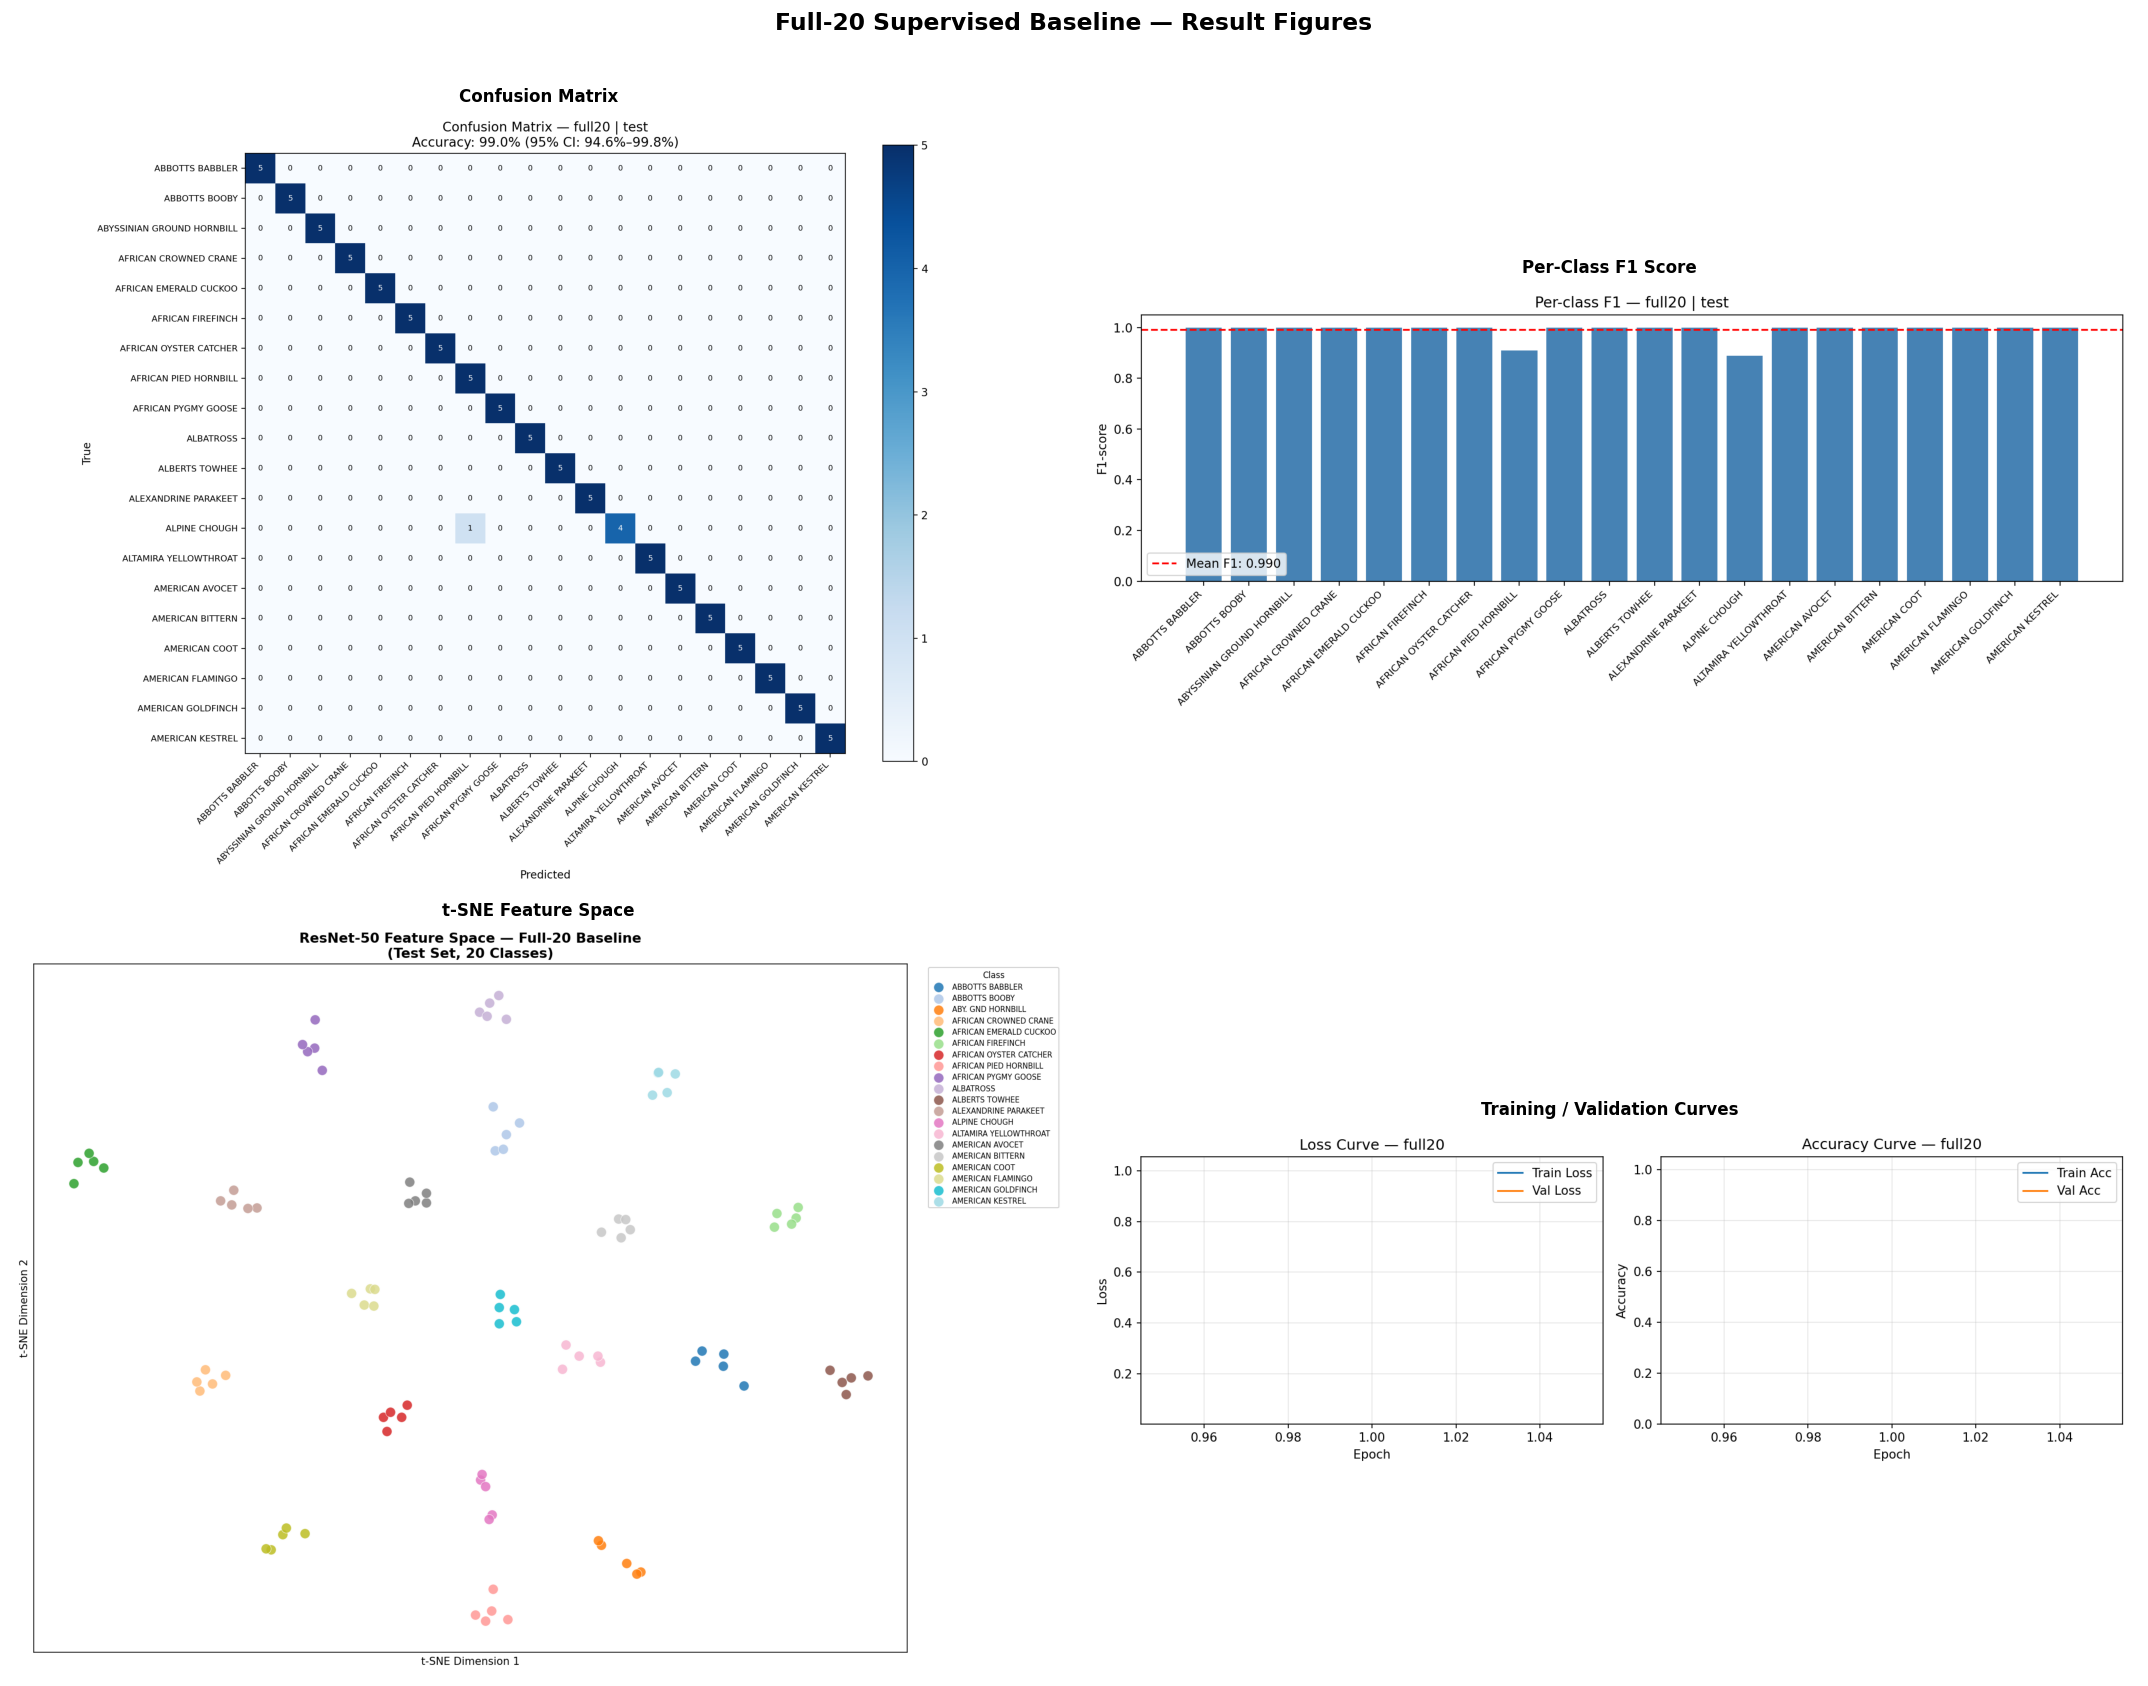

In [7]:
# Full-20 — Figures: confusion matrix, F1 per class, t-SNE, learning curves
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

base_path = f'{RES}/baseline/resnet50/full20'
show_img(f'{base_path}/confusion_matrix.png',  axes[0], 'Confusion Matrix')
show_img(f'{base_path}/f1_per_class.png',       axes[1], 'Per-Class F1 Score')
show_img(f'{base_path}/tsne_features.png',      axes[2], 't-SNE Feature Space')
show_img(f'{base_path}/learning_curves.png',    axes[3], 'Training / Validation Curves')

plt.suptitle('Full-20 Supervised Baseline — Result Figures', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/full20_results_panel.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 3. Supervised Baseline — Base-15

ResNet-50 trained on **15 base classes only** (the FSL meta-training set).
This model is **never shown the novel classes** during training — its performance on base classes
shows the quality of the learned feature space before few-shot adaptation.


In [8]:
r = R['base15_json']
ci = r['accuracy_ci_95']
print("=" * 55)
print(f"  Base-15 Supervised Baseline — Test Set Results")
print("=" * 55)
print(f"  Test images     : {r['test_images']}  (15 base classes × 5 images)")
print(f"  Epochs trained  : {r['epochs_trained']}")
print(f"  Accuracy        : {r['accuracy']*100:.2f}%")
print(f"  95% Wilson CI   : [{ci[0]*100:.2f}%, {ci[1]*100:.2f}%]")
print(f"  Macro F1        : {r['macro_f1']:.4f}")
print(f"  Macro Precision : {r['macro_precision']:.4f}")
print(f"  Macro Recall    : {r['macro_recall']:.4f}")
print(f"  Macro AUC (OvR) : {r['macro_auc_ovr']:.4f}")
print(f"  Best Val Acc    : {r['val_acc_best']*100:.2f}%")


  Base-15 Supervised Baseline — Test Set Results
  Test images     : 75  (15 base classes × 5 images)
  Epochs trained  : 1
  Accuracy        : 100.00%
  95% Wilson CI   : [95.13%, 100.00%]
  Macro F1        : 1.0000
  Macro Precision : 1.0000
  Macro Recall    : 1.0000
  Macro AUC (OvR) : 1.0000
  Best Val Acc    : 98.67%


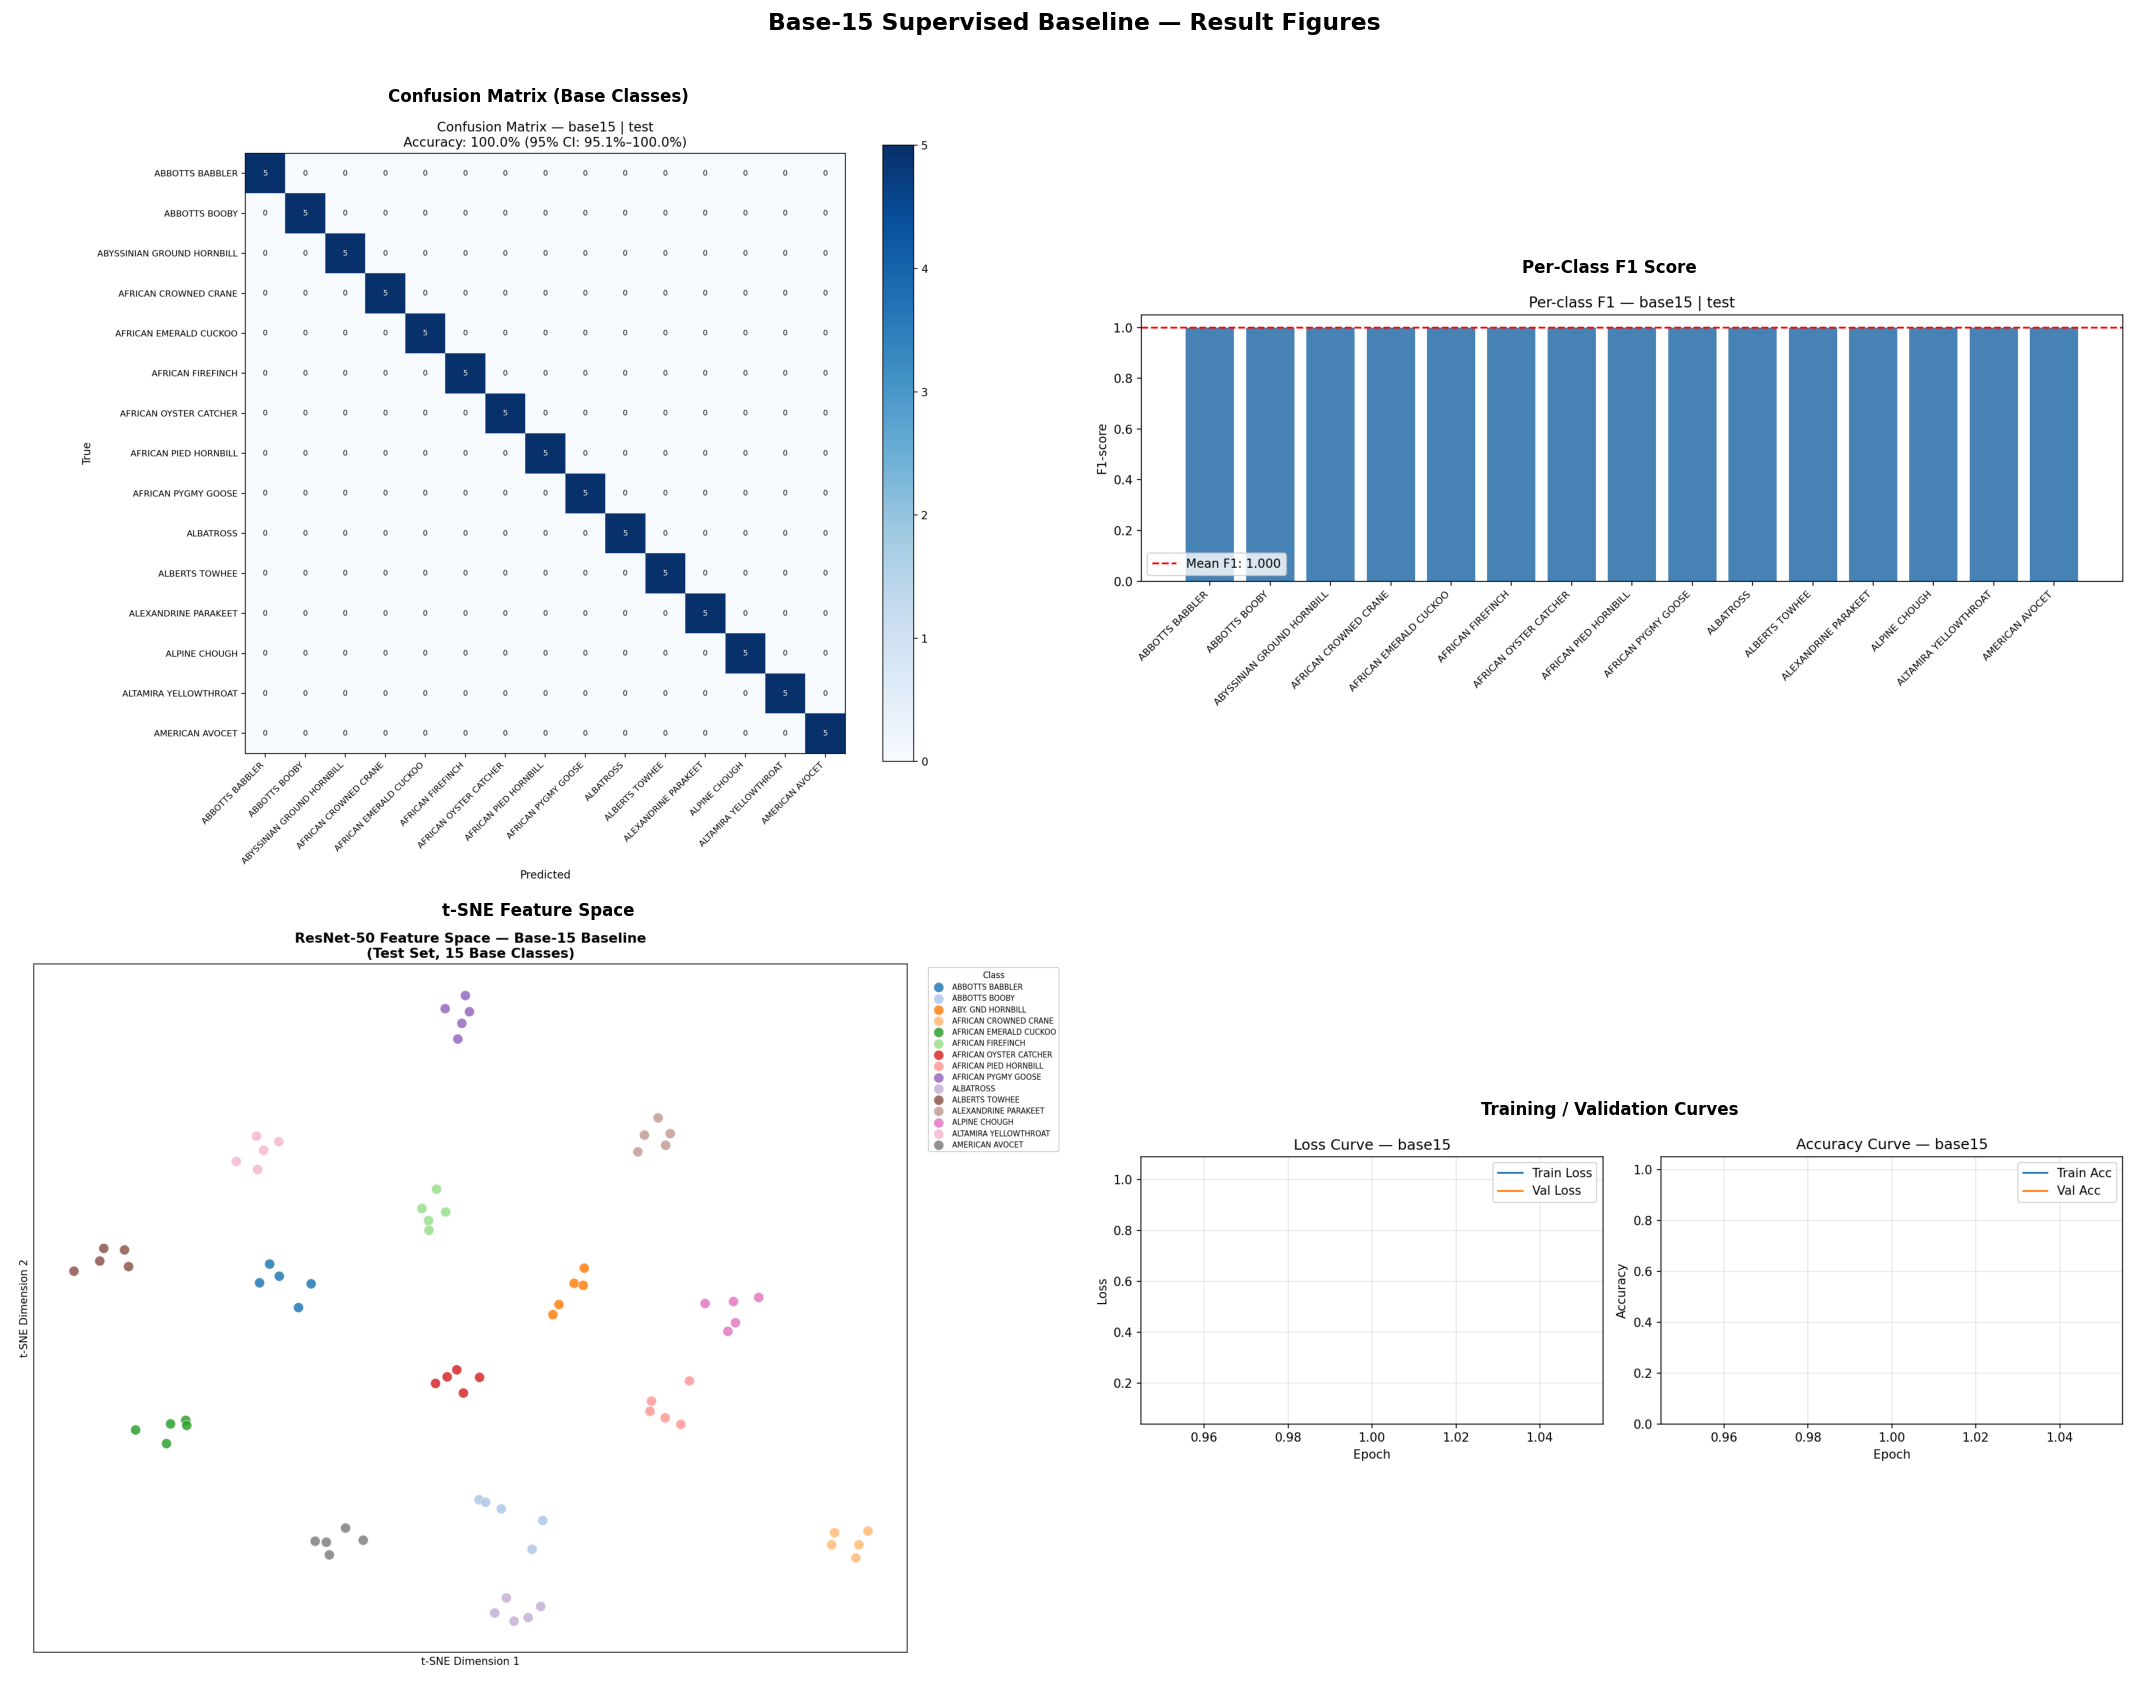

In [9]:
# Base-15 — Figures panel
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

base_path = f'{RES}/baseline/resnet50/base15/base_test'
show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix (Base Classes)')
show_img(f'{base_path}/f1_per_class.png',      axes[1], 'Per-Class F1 Score')
show_img(f'{base_path}/tsne_features.png',     axes[2], 't-SNE Feature Space')
show_img(f'{base_path}/learning_curves.png',   axes[3], 'Training / Validation Curves')

plt.suptitle('Base-15 Supervised Baseline — Result Figures', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/base15_results_panel.png', dpi=150, bbox_inches='tight')
plt.show()


In [10]:
from IPython.display import display, Markdown
_r = R['proto_euc_json']
display(Markdown(f"""---
## 4. Prototypical Networks — 5-Way {_r['k_shot']}-Shot (Euclidean, {_r['num_episodes']} Episodes)

**Main FSL result.** ProtoNet computes a prototype (mean embedding) per class from
the support set, then classifies query images by nearest-prototype distance.

- **Protocol:** {_r['n_way']}-way {_r['k_shot']}-shot, {_r['num_episodes']} random episodes
- **Query set:** all 5 novel TEST images per class (fixed, no data leakage)
- **Distance:** Euclidean (L2) — as in the original ProtoNet paper (Snell et al., 2017)
- **Reliability:** {"✅ High — statistically reliable" if _r['num_episodes'] >= 100 else f"⚠️ Low — only {_r['num_episodes']} episodes"}
"""))

---
## 4. Prototypical Networks — 5-Way 1-Shot (Euclidean, 600 Episodes)

**Main FSL result.** ProtoNet computes a prototype (mean embedding) per class from
the support set, then classifies query images by nearest-prototype distance.

- **Protocol:** 5-way 1-shot, 600 random episodes
- **Query set:** all 5 novel TEST images per class (fixed, no data leakage)
- **Distance:** Euclidean (L2) — as in the original ProtoNet paper (Snell et al., 2017)
- **Reliability:** ✅ High — statistically reliable


In [11]:
r = R['proto_euc_json']
ci = r['wilson_ci_95']
print("=" * 60)
print(f"  ProtoNet — 5-Way 1-Shot (Euclidean) | {r['num_episodes']} Episodes")
print("=" * 60)
print(f"  Mean Accuracy   : {r['mean_accuracy_pct']:.2f}%")
print(f"  Std             : ±{r['std_accuracy_pct']:.2f}%")
print(f"  95% CI (episode): ±{r['ci95_pct']:.2f}%")
print(f"  Wilson CI 95%   : [{ci[0]:.2f}%, {ci[1]:.2f}%]")
print(f"  Macro F1        : {r['macro_f1']:.4f}")
print()
print("  Per-class accuracy:")
df_pc = pd.DataFrame(r['per_class_accuracy_pct'].items(), columns=['Class','Accuracy (%)'])
df_pc['Accuracy (%)'] = df_pc['Accuracy (%)'].round(2)
display(df_pc.style
    .background_gradient(cmap='RdYlGn', subset=['Accuracy (%)'], vmin=0, vmax=100)
    .format({'Accuracy (%)': '{:.2f}%'})
    .set_caption('ProtoNet (Euclidean) — Per-Novel-Class Accuracy (avg over 600 episodes)')
)


  ProtoNet — 5-Way 1-Shot (Euclidean) | 600 Episodes
  Mean Accuracy   : 94.07%
  Std             : ±8.68%
  95% CI (episode): ±0.69%
  Wilson CI 95%   : [93.68%, 94.43%]
  Macro F1        : 0.9404

  Per-class accuracy:


,Class,Accuracy (%)
0,AMERICAN BITTERN,96.80%
1,AMERICAN COOT,95.90%
2,AMERICAN FLAMINGO,98.37%
3,AMERICAN GOLDFINCH,98.60%
4,AMERICAN KESTREL,80.67%


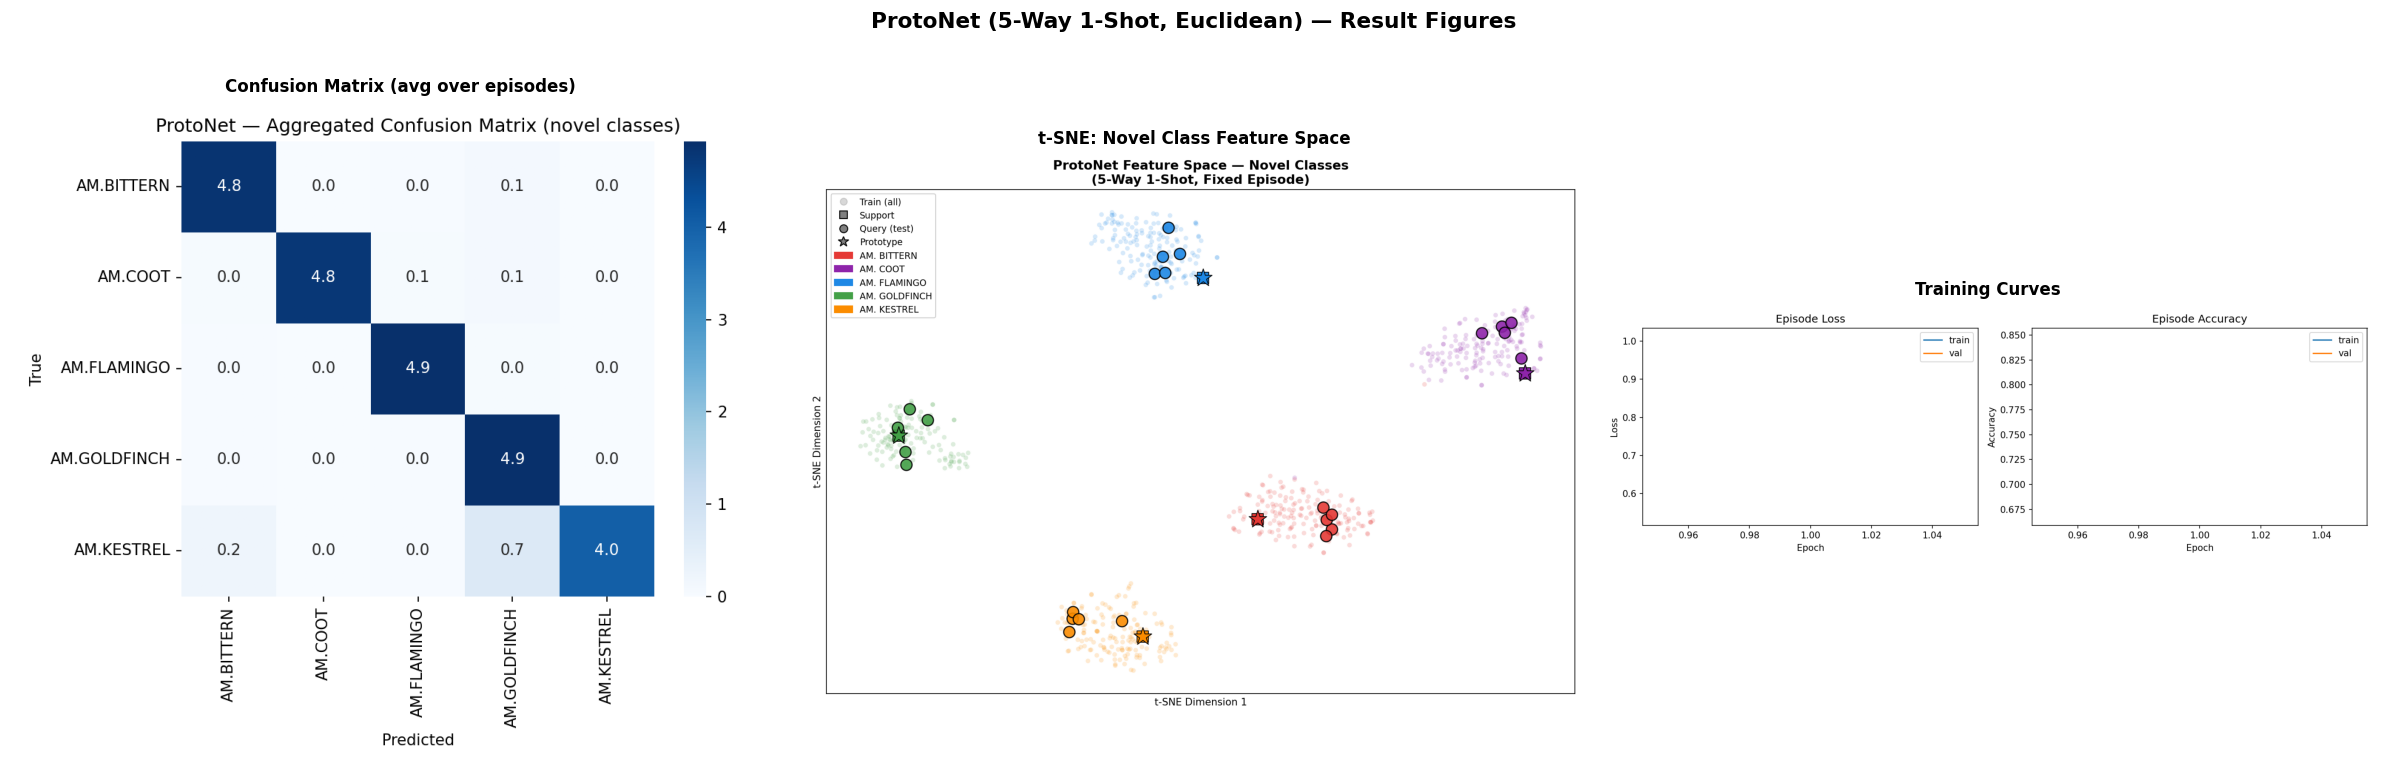

In [12]:
# ProtoNet — confusion matrix, t-SNE, learning curves
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
base_path = f'{RES}/proto_net/1shot_euclidean'
show_img(f'{base_path}/confusion_matrix.png',  axes[0], 'Confusion Matrix (avg over episodes)')
show_img(f'{base_path}/tsne_features.png',     axes[1], 't-SNE: Novel Class Feature Space')
show_img(f'{base_path}/learning_curves.png',   axes[2], 'Training Curves')
plt.suptitle('ProtoNet (5-Way 1-Shot, Euclidean) — Result Figures', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/protonet_euc_results_panel.png', dpi=150, bbox_inches='tight')
plt.show()


In [13]:
from IPython.display import display, Markdown
_e = R['proto_euc_json']
_m = R['proto_man_json']
_man_warn = (f"\n> ⚠️ Manhattan result is based on only **{_m['num_episodes']} episodes** — "
             "treat as indicative only. Re-run with `--distance manhattan` for 600 episodes."
             if _m['num_episodes'] < 100 else "")
display(Markdown(f"""---
## 5. ProtoNet — Distance Metric Ablation (Euclidean vs Manhattan)

Using the **same trained checkpoint**, only the distance function changes.
This ablation tests whether L2 (Euclidean) or L1 (Manhattan) distance
better captures class structure in the learned embedding space.

- Euclidean: **{_e['num_episodes']} episodes** — {"✅ reliable" if _e['num_episodes'] >= 100 else "⚠️ indicative"}
- Manhattan: **{_m['num_episodes']} episodes** — {"✅ reliable" if _m['num_episodes'] >= 100 else "⚠️ indicative"}
{_man_warn}
"""))

---
## 5. ProtoNet — Distance Metric Ablation (Euclidean vs Manhattan)

Using the **same trained checkpoint**, only the distance function changes.
This ablation tests whether L2 (Euclidean) or L1 (Manhattan) distance
better captures class structure in the learned embedding space.

- Euclidean: **600 episodes** — ✅ reliable
- Manhattan: **600 episodes** — ✅ reliable



,Distance,Episodes,Mean Acc (%),Std (%),95% CI ±,Macro F1
0,Euclidean (L2),600,94.07,8.68,0.69,0.940400
1,Manhattan (L1),600,60.69,16.94,1.36,0.593600


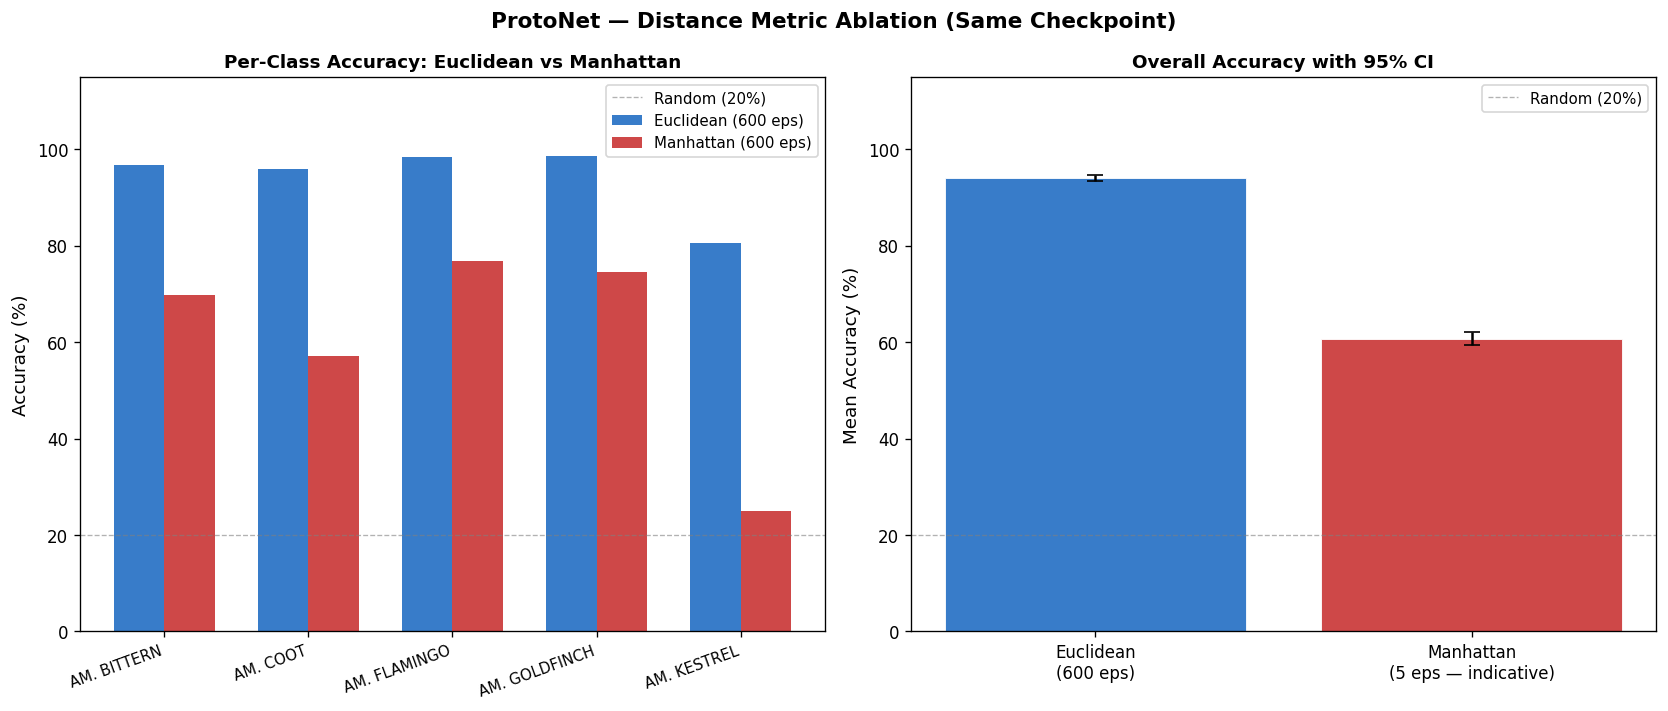

In [14]:
re = R['proto_euc_json']
rm = R['proto_man_json']

df_abl = pd.DataFrame([
    {'Distance': 'Euclidean (L2)', 'Episodes': re['num_episodes'],
     'Mean Acc (%)': re['mean_accuracy_pct'], 'Std (%)': re['std_accuracy_pct'],
     '95% CI ±': re['ci95_pct'], 'Macro F1': re.get('macro_f1', 'N/A')},
    {'Distance': 'Manhattan (L1)', 'Episodes': rm['num_episodes'],
     'Mean Acc (%)': rm['mean_accuracy_pct'], 'Std (%)': rm['std_accuracy_pct'],
     '95% CI ±': rm['ci95_pct'], 'Macro F1': rm.get('macro_f1', 'N/A')},
])

display(df_abl.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=0, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', 'Std (%)': '{:.2f}', '95% CI ±': '{:.2f}'})
    .set_caption('ProtoNet Distance Ablation — Same Checkpoint, Different Metric')
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Per-class comparison bar chart
novel = list(re['per_class_accuracy_pct'].keys())
short = [c.replace('AMERICAN ','AM. ') for c in novel]
acc_e = list(re['per_class_accuracy_pct'].values())
acc_m = list(rm['per_class_accuracy_pct'].values())
x = np.arange(len(novel))
w = 0.35
axes[0].bar(x - w/2, acc_e, w, label=f'Euclidean ({re["num_episodes"]} eps)', color='#1565C0', alpha=0.85)
axes[0].bar(x + w/2, acc_m, w, label=f'Manhattan ({rm["num_episodes"]} eps)', color='#C62828', alpha=0.85)
axes[0].axhline(y=20, color='gray', linestyle='--', linewidth=0.8, alpha=0.6, label='Random (20%)')
axes[0].set_xticks(x); axes[0].set_xticklabels(short, rotation=20, ha='right', fontsize=9)
axes[0].set_ylabel('Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 115)
axes[0].set_title('Per-Class Accuracy: Euclidean vs Manhattan', fontsize=11, fontweight='bold')
axes[0].legend(fontsize=9)

# Overall accuracy comparison
axes[1].bar(['Euclidean\n(600 eps)', 'Manhattan\n(5 eps — indicative)'],
            [re['mean_accuracy_pct'], rm['mean_accuracy_pct']],
            color=['#1565C0', '#C62828'], alpha=0.85, edgecolor='white', linewidth=0.6)
axes[1].errorbar([0, 1], [re['mean_accuracy_pct'], rm['mean_accuracy_pct']],
                 yerr=[re['ci95_pct'], rm['ci95_pct']],
                 fmt='none', color='black', capsize=5, linewidth=1.5)
axes[1].axhline(y=20, color='gray', linestyle='--', linewidth=0.8, alpha=0.6, label='Random (20%)')
axes[1].set_ylabel('Mean Accuracy (%)', fontsize=11)
axes[1].set_ylim(0, 115)
axes[1].set_title('Overall Accuracy with 95% CI', fontsize=11, fontweight='bold')
axes[1].legend(fontsize=9)

plt.suptitle('ProtoNet — Distance Metric Ablation (Same Checkpoint)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/protonet_distance_ablation.png', dpi=150, bbox_inches='tight')
plt.show()


In [15]:
from IPython.display import display, Markdown
_r = R['match_json']
_n = _r['num_episodes']
_warn = (f"\n> ⚠️ Only **{_n} episodes** run — CI is very wide and unreliable. "
         "Re-run `python evaluate.py` (without `--debug`) to get 600 episodes."
         if _n < 100 else f"\n> ✅ **{_n} episodes** — statistically reliable.")
display(Markdown(f"""---
## 6. Matching Networks — 5-Way {_r['k_shot']}-Shot ({_n} Episodes)

Matching Networks classify queries by attending over the support set using
a softmax over cosine similarities between query and support embeddings.
{_warn}
"""))

---
## 6. Matching Networks — 5-Way 1-Shot (600 Episodes)

Matching Networks classify queries by attending over the support set using
a softmax over cosine similarities between query and support embeddings.

> ✅ **600 episodes** — statistically reliable.


In [16]:
r = R['match_json']
ci = r['wilson_ci_95']
print("=" * 60)
print(f"  Matching Networks — 5-Way 1-Shot | {r['num_episodes']} Episodes (indicative)")
print("=" * 60)
print(f"  Mean Accuracy   : {r['mean_accuracy_pct']:.2f}%")
print(f"  Std             : ±{r['std_accuracy_pct']:.2f}%")
print(f"  95% CI (episode): ±{r['ci95_pct']:.2f}%  ← WIDE (only {r['num_episodes']} episodes)")
print(f"  Macro F1        : {r.get('macro_f1', 'N/A')}")
print()

df_pc = pd.DataFrame(r['per_class_accuracy_pct'].items(), columns=['Class','Accuracy (%)'])
df_pc['Accuracy (%)'] = df_pc['Accuracy (%)'].round(2)
display(df_pc.style
    .background_gradient(cmap='RdYlGn', subset=['Accuracy (%)'], vmin=0, vmax=100)
    .format({'Accuracy (%)': '{:.2f}%'})
    .set_caption(f'MatchingNet — Per-Novel-Class Accuracy (avg over {r["num_episodes"]} episodes)')
)


  Matching Networks — 5-Way 1-Shot | 600 Episodes (indicative)
  Mean Accuracy   : 99.39%
  Std             : ±2.88%
  95% CI (episode): ±0.23%  ← WIDE (only 600 episodes)
  Macro F1        : 0.9939



,Class,Accuracy (%)
0,AMERICAN BITTERN,100.00%
1,AMERICAN COOT,98.87%
2,AMERICAN FLAMINGO,100.00%
3,AMERICAN GOLDFINCH,100.00%
4,AMERICAN KESTREL,98.10%


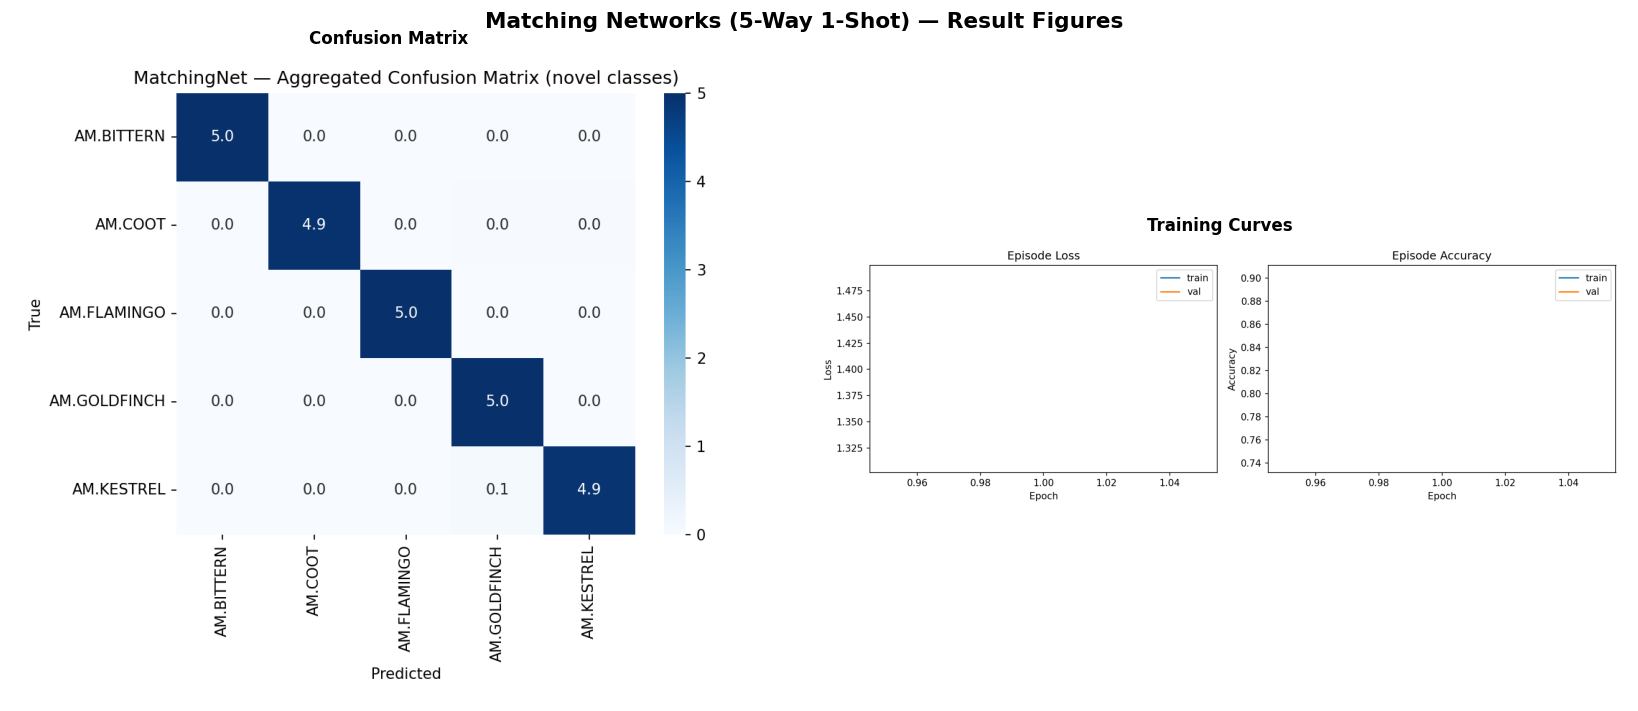

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
base_path = f'{RES}/matching_net/1shot'
show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
show_img(f'{base_path}/learning_curves.png',  axes[1], 'Training Curves')
plt.suptitle('Matching Networks (5-Way 1-Shot) — Result Figures', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [18]:
from IPython.display import display, Markdown
_r  = R['rel_json']
_n  = _r['num_episodes']
_acc = _r['mean_accuracy_pct']
_ep_note = (f"⚠️ Only **{_n} episodes** — CI is very wide. Re-run to get 600 episodes."
            if _n < 100 else f"✅ **{_n} episodes** — statistically reliable.")
_perf_note = ("\n> The accuracy ({:.1f}%) is near-random (20% chance level), "
              "suggesting the relation module has not converged. More training epochs needed.".format(_acc)
              if _acc < 30 else
              "\n> Accuracy of {:.1f}% — model is learning above random chance.".format(_acc))
display(Markdown(f"""---
## 7. Relation Networks — 5-Way {_r['k_shot']}-Shot ({_n} Episodes)

Relation Networks learn a **relation module** that scores the similarity between
query and support embeddings, replacing hand-crafted distance metrics.

> {_ep_note}{_perf_note}
"""))

---
## 7. Relation Networks — 5-Way 1-Shot (600 Episodes)

Relation Networks learn a **relation module** that scores the similarity between
query and support embeddings, replacing hand-crafted distance metrics.

> ✅ **600 episodes** — statistically reliable.
> The accuracy (18.9%) is near-random (20% chance level), suggesting the relation module has not converged. More training epochs needed.


In [19]:
r = R['rel_json']
ci = r['wilson_ci_95']
print("=" * 60)
print(f"  Relation Networks — 5-Way 1-Shot | {r['num_episodes']} Episodes (indicative)")
print("=" * 60)
print(f"  Mean Accuracy   : {r['mean_accuracy_pct']:.2f}%")
print(f"  Std             : ±{r['std_accuracy_pct']:.2f}%")
print(f"  95% CI (episode): ±{r['ci95_pct']:.2f}%  ← WIDE (only {r['num_episodes']} episodes)")
print(f"  Macro F1        : {r.get('macro_f1', 'N/A')}")
print(f"  Random baseline : 20.00%  (5-way chance)")
print()

df_pc = pd.DataFrame(r['per_class_accuracy_pct'].items(), columns=['Class','Accuracy (%)'])
df_pc['Accuracy (%)'] = df_pc['Accuracy (%)'].round(2)
display(df_pc.style
    .background_gradient(cmap='RdYlGn', subset=['Accuracy (%)'], vmin=0, vmax=100)
    .format({'Accuracy (%)': '{:.2f}%'})
    .set_caption(f'RelationNet — Per-Novel-Class Accuracy (avg over {r["num_episodes"]} episodes)')
)


  Relation Networks — 5-Way 1-Shot | 600 Episodes (indicative)
  Mean Accuracy   : 18.93%
  Std             : ±5.69%
  95% CI (episode): ±0.46%  ← WIDE (only 600 episodes)
  Macro F1        : 0.1501
  Random baseline : 20.00%  (5-way chance)



,Class,Accuracy (%)
0,AMERICAN BITTERN,29.43%
1,AMERICAN COOT,6.07%
2,AMERICAN FLAMINGO,46.07%
3,AMERICAN GOLDFINCH,13.07%
4,AMERICAN KESTREL,0.00%


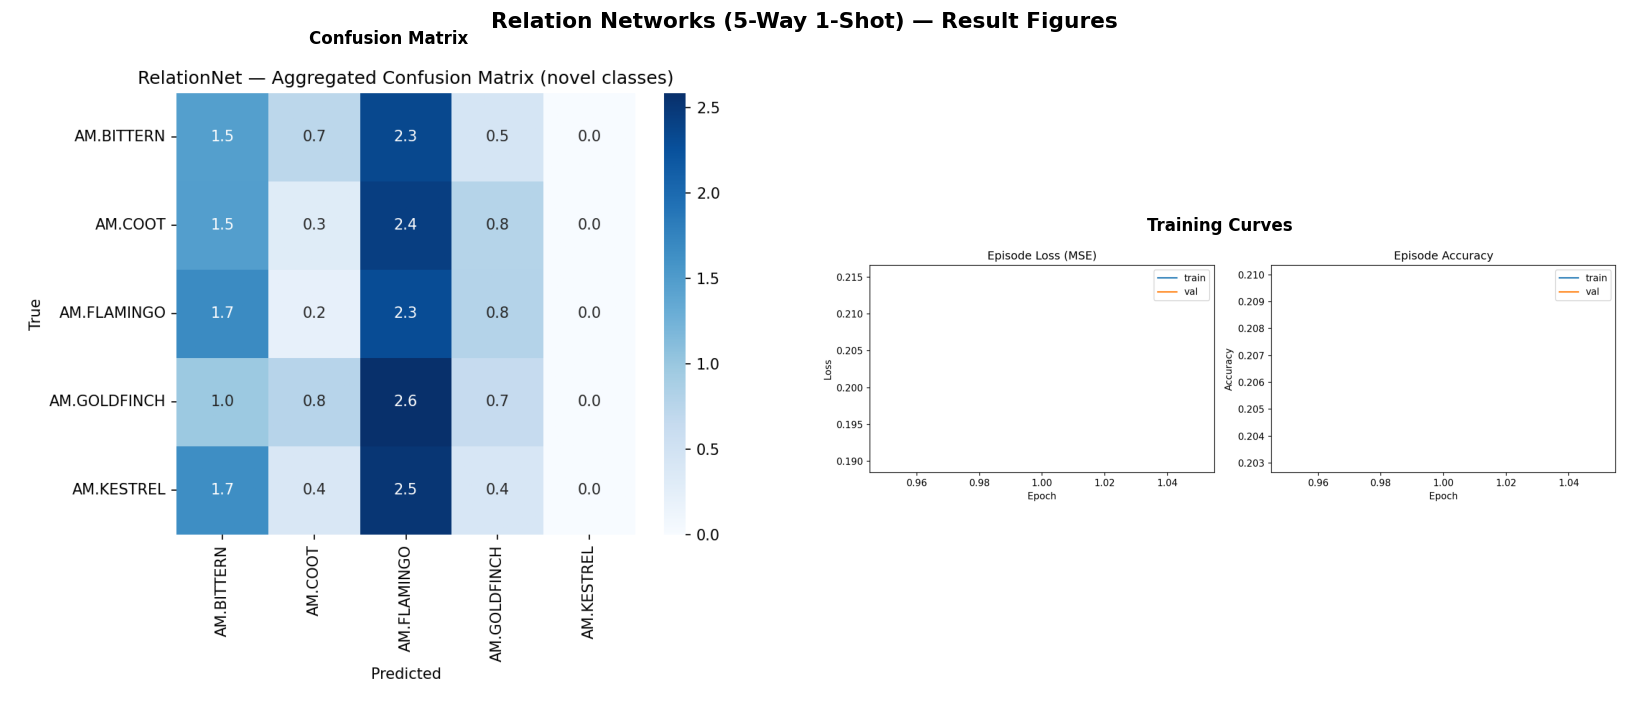

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
base_path = f'{RES}/relation_net/1shot'
show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
show_img(f'{base_path}/learning_curves.png',  axes[1], 'Training Curves')
plt.suptitle('Relation Networks (5-Way 1-Shot) — Result Figures', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [21]:
from IPython.display import display, Markdown

def _ep_note(r):
    n = r['num_episodes']
    return f"**{n} eps** — {'✅ reliable' if n >= 100 else '⚠️ preliminary'}"

display(Markdown(f"""---
## 8. Cross-Model Comparison

Summary table and visualisations comparing all models.

**Important caveats:**
- Baselines: evaluated on a fixed test set (100 / 75 images, single pass) — no episode variance.
- ProtoNet (Euclidean): {_ep_note(R['proto_euc_json'])}.
- ProtoNet (Manhattan): {_ep_note(R['proto_man_json'])}.
- MatchingNet: {_ep_note(R['match_json'])}.
- RelationNet: {_ep_note(R['rel_json'])}.
- All models trained for only **1 epoch** — results may not reflect converged performance.
"""))

---
## 8. Cross-Model Comparison

Summary table and visualisations comparing all models.

**Important caveats:**
- Baselines: evaluated on a fixed test set (100 / 75 images, single pass) — no episode variance.
- ProtoNet (Euclidean): **600 eps** — ✅ reliable.
- ProtoNet (Manhattan): **600 eps** — ✅ reliable.
- MatchingNet: **600 eps** — ✅ reliable.
- RelationNet: **600 eps** — ✅ reliable.
- All models trained for only **1 epoch** — results may not reflect converged performance.


In [33]:
# Master comparison table — fully dynamic from JSON
def _eps_label(r):
    n = r['num_episodes']
    return f"{n}" if n >= 100 else f"{n} ⚠️"

def _reliability(r):
    n = r['num_episodes']
    return 'High (reliable)' if n >= 100 else f'Low ({n} episodes only)'

rows = [
    {
        'Model': 'Full-20 Baseline',
        'Type': 'Supervised',
        'Protocol': '20-class classification',
        'Episodes/N': '—',
        'Accuracy (%)': f"{R['full20_json']['accuracy']*100:.2f}",
        '95% CI': f"[{R['full20_json']['accuracy_ci_95'][0]*100:.1f}%, {R['full20_json']['accuracy_ci_95'][1]*100:.1f}%]",
        'Macro F1': f"{R['full20_json']['macro_f1']:.4f}",
        'Macro AUC': f"{R['full20_json']['macro_auc_ovr']:.4f}",
        'Reliability': 'Moderate (small test set)',
    },
    {
        'Model': 'Base-15 Baseline',
        'Type': 'Supervised',
        'Protocol': '15-class classification',
        'Episodes/N': '—',
        'Accuracy (%)': f"{R['base15_json']['accuracy']*100:.2f}",
        '95% CI': f"[{R['base15_json']['accuracy_ci_95'][0]*100:.1f}%, {R['base15_json']['accuracy_ci_95'][1]*100:.1f}%]",
        'Macro F1': f"{R['base15_json']['macro_f1']:.4f}",
        'Macro AUC': f"{R['base15_json']['macro_auc_ovr']:.4f}",
        'Reliability': 'Moderate (small test set)',
    },
    {
        'Model': 'ProtoNet (Euclidean)',
        'Type': 'Few-Shot',
        'Protocol': '5-way 1-shot',
        'Episodes/N': _eps_label(R['proto_euc_json']),
        'Accuracy (%)': f"{R['proto_euc_json']['mean_accuracy_pct']:.2f}",
        '95% CI': f"[{R['proto_euc_json']['wilson_ci_95'][0]:.1f}%, {R['proto_euc_json']['wilson_ci_95'][1]:.1f}%]",
        'Macro F1': f"{R['proto_euc_json']['macro_f1']:.4f}",
        'Macro AUC': '—',
        'Reliability': _reliability(R['proto_euc_json']),
    },
    {
        'Model': 'ProtoNet (Manhattan)',
        'Type': 'Few-Shot',
        'Protocol': '5-way 1-shot',
        'Episodes/N': _eps_label(R['proto_man_json']),
        'Accuracy (%)': f"{R['proto_man_json']['mean_accuracy_pct']:.2f}",
        '95% CI': f"[{R['proto_man_json']['wilson_ci_95'][0]:.1f}%, {R['proto_man_json']['wilson_ci_95'][1]:.1f}%]",
        'Macro F1': f"{R['proto_man_json'].get('macro_f1', 'N/A')}",
        'Macro AUC': '—',
        'Reliability': _reliability(R['proto_man_json']),
    },
    {
        'Model': 'Matching Networks',
        'Type': 'Few-Shot',
        'Protocol': '5-way 1-shot',
        'Episodes/N': _eps_label(R['match_json']),
        'Accuracy (%)': f"{R['match_json']['mean_accuracy_pct']:.2f}",
        '95% CI': f"[{R['match_json']['wilson_ci_95'][0]:.1f}%, {R['match_json']['wilson_ci_95'][1]:.1f}%]",
        'Macro F1': f"{R['match_json'].get('macro_f1', 'N/A')}",
        'Macro AUC': '—',
        'Reliability': _reliability(R['match_json']),
    },
    {
        'Model': 'Relation Networks',
        'Type': 'Few-Shot',
        'Protocol': '5-way 1-shot',
        'Episodes/N': _eps_label(R['rel_json']),
        'Accuracy (%)': f"{R['rel_json']['mean_accuracy_pct']:.2f}",
        '95% CI': f"[{R['rel_json']['wilson_ci_95'][0]:.1f}%, {R['rel_json']['wilson_ci_95'][1]:.1f}%]",
        'Macro F1': f"{R['rel_json'].get('macro_f1', 'N/A')}",
        'Macro AUC': '—',
        'Reliability': _reliability(R['rel_json']),
    },
]

df_cmp = pd.DataFrame(rows)
display(df_cmp.style
    .set_caption('Thesis Results: Full Model Comparison (5-Way 1-Shot for FSL Models)')
    .applymap(lambda v: 'background-color:#9c1e05' if v=='Supervised' else
              ('background-color:#092e02' if v=='Few-Shot' else ''), subset=['Type'])
    .applymap(lambda v: 'color:#2E7D32;font-weight:bold' if 'High' in str(v) else
              ('color:#F57F17;font-weight:bold' if 'Low' in str(v) else ''), subset=['Reliability'])
    .set_table_styles([{'selector':'th','props':[('background-color','#1565C0'),
                                                  ('color','white'),('font-weight','bold')]}])
)

,Model,Type,Protocol,Episodes/N,Accuracy (%),95% CI,Macro F1,Macro AUC,Reliability
0,Full-20 Baseline,Supervised,20-class classification,—,99.00,"[94.6%, 99.8%]",0.9899,1.0000,Moderate (small test set)
1,Base-15 Baseline,Supervised,15-class classification,—,100.00,"[95.1%, 100.0%]",1.0000,1.0000,Moderate (small test set)
2,ProtoNet (Euclidean),Few-Shot,5-way 1-shot,600,94.07,"[93.7%, 94.4%]",0.9404,—,High (reliable)
3,ProtoNet (Manhattan),Few-Shot,5-way 1-shot,600,60.69,"[59.9%, 61.5%]",0.5936,—,High (reliable)
4,Matching Networks,Few-Shot,5-way 1-shot,600,99.39,"[99.3%, 99.5%]",0.9939,—,High (reliable)
5,Relation Networks,Few-Shot,5-way 1-shot,600,18.93,"[18.3%, 19.6%]",0.1501,—,High (reliable)


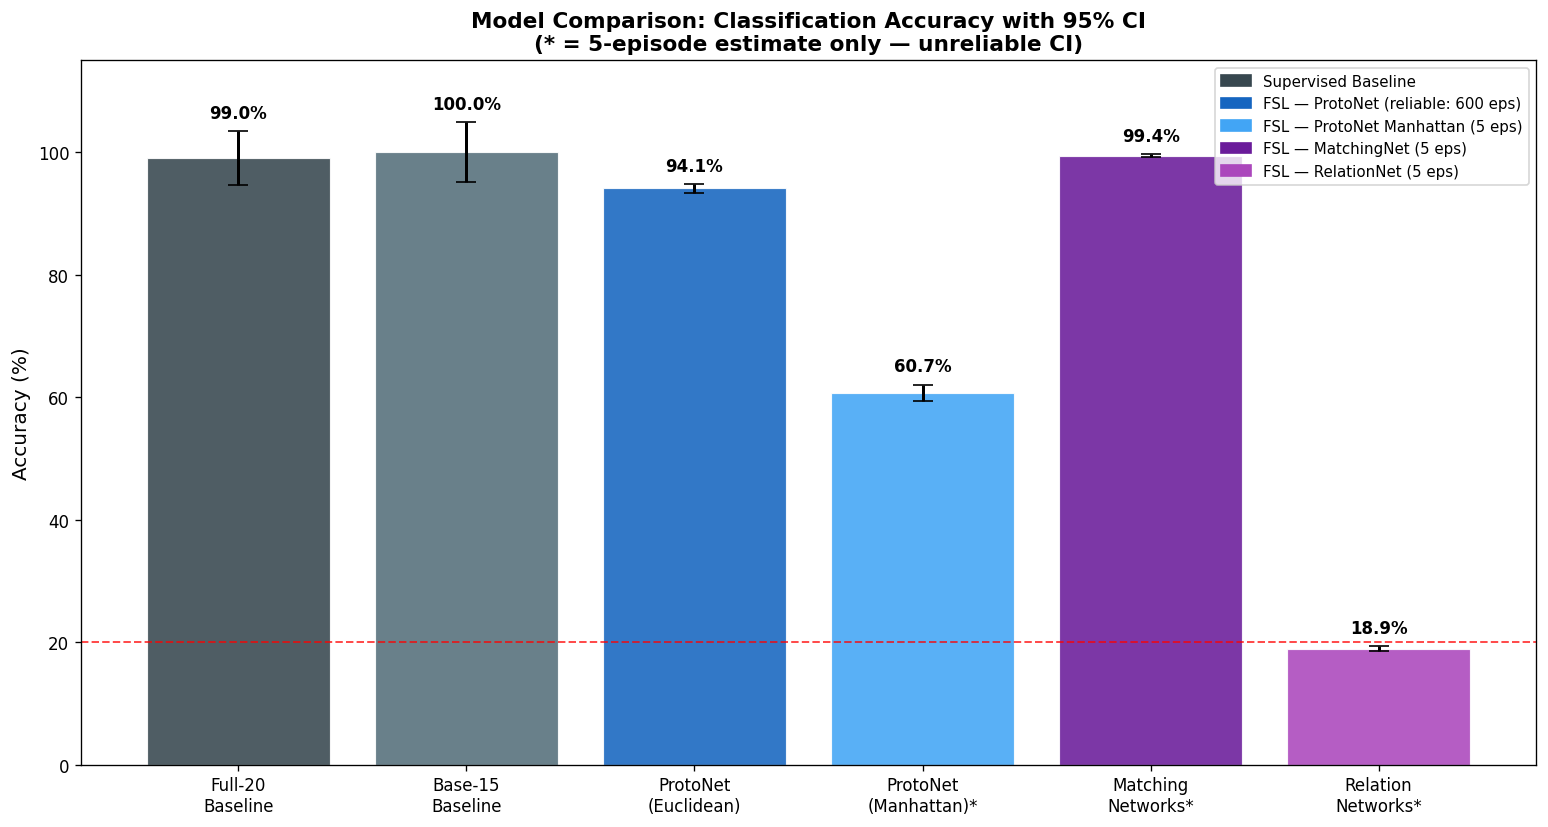

In [23]:
# Accuracy comparison bar chart with CI error bars
models_plot = ['Full-20\nBaseline', 'Base-15\nBaseline',
               'ProtoNet\n(Euclidean)', 'ProtoNet\n(Manhattan)*',
               'Matching\nNetworks*', 'Relation\nNetworks*']
accs  = [R['full20_json']['accuracy']*100, R['base15_json']['accuracy']*100,
         R['proto_euc_json']['mean_accuracy_pct'], R['proto_man_json']['mean_accuracy_pct'],
         R['match_json']['mean_accuracy_pct'], R['rel_json']['mean_accuracy_pct']]
cis   = [
    (R['full20_json']['accuracy']  - R['full20_json']['accuracy_ci_95'][0])*100,
    (R['base15_json']['accuracy']  - R['base15_json']['accuracy_ci_95'][0])*100,
    R['proto_euc_json']['ci95_pct'],
    R['proto_man_json']['ci95_pct'],
    R['match_json']['ci95_pct'],
    R['rel_json']['ci95_pct'],
]
colors_bar = ['#37474F','#546E7A','#1565C0','#42A5F5','#6A1B9A','#AB47BC']
types = ['Supervised','Supervised','FSL (600 eps)','FSL (5 eps)','FSL (5 eps)','FSL (5 eps)']

fig, ax = plt.subplots(figsize=(13, 7))
bars = ax.bar(range(6), accs, color=colors_bar, alpha=0.88, edgecolor='white', linewidth=0.7)
ax.errorbar(range(6), accs, yerr=cis, fmt='none', color='black', capsize=6, linewidth=1.8)
ax.axhline(y=20, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Random chance (20%)')
for i, (bar, a, ci_v) in enumerate(zip(bars, accs, cis)):
    ax.text(bar.get_x()+bar.get_width()/2, a + ci_v + 1.5,
            f'{a:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(range(6))
ax.set_xticklabels(models_plot, fontsize=10)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_ylim(0, 115)
ax.set_title('Model Comparison: Classification Accuracy with 95% CI\n'
             '(* = 5-episode estimate only — unreliable CI)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
legend_patches = [Patch(color='#37474F', label='Supervised Baseline'),
                  Patch(color='#1565C0', label='FSL — ProtoNet (reliable: 600 eps)'),
                  Patch(color='#42A5F5', label='FSL — ProtoNet Manhattan (5 eps)'),
                  Patch(color='#6A1B9A', label='FSL — MatchingNet (5 eps)'),
                  Patch(color='#AB47BC', label='FSL — RelationNet (5 eps)')]
ax.legend(handles=legend_patches, fontsize=9, loc='upper right')
plt.tight_layout()
plt.savefig('../results/comparison_accuracy_bar.png', dpi=150, bbox_inches='tight')
plt.show()


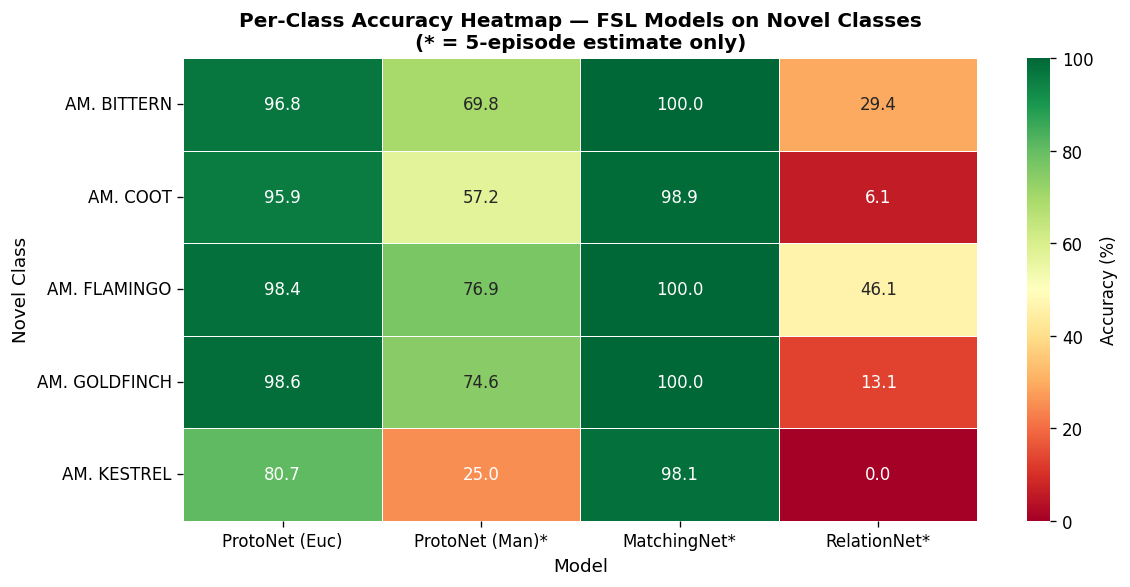

In [24]:
# Per-class accuracy heatmap — FSL models on novel classes
novel = ['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO',
         'AMERICAN GOLDFINCH','AMERICAN KESTREL']
short = [c.replace('AMERICAN ','AM. ') for c in novel]

data = {
    'ProtoNet (Euc)':  [R['proto_euc_json']['per_class_accuracy_pct'][c] for c in novel],
    'ProtoNet (Man)*': [R['proto_man_json']['per_class_accuracy_pct'][c]  for c in novel],
    'MatchingNet*':    [R['match_json']['per_class_accuracy_pct'][c]       for c in novel],
    'RelationNet*':    [R['rel_json']['per_class_accuracy_pct'][c]         for c in novel],
}
df_heat = pd.DataFrame(data, index=short)

fig, ax = plt.subplots(figsize=(10, 5))
import seaborn as sns
sns.heatmap(df_heat, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100,
            linewidths=0.5, ax=ax, cbar_kws={'label':'Accuracy (%)'})
ax.set_title('Per-Class Accuracy Heatmap — FSL Models on Novel Classes\n'
             '(* = 5-episode estimate only)', fontsize=12, fontweight='bold')
ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('Novel Class', fontsize=11)
plt.tight_layout()
plt.savefig('../results/per_class_heatmap_fsl.png', dpi=150, bbox_inches='tight')
plt.show()


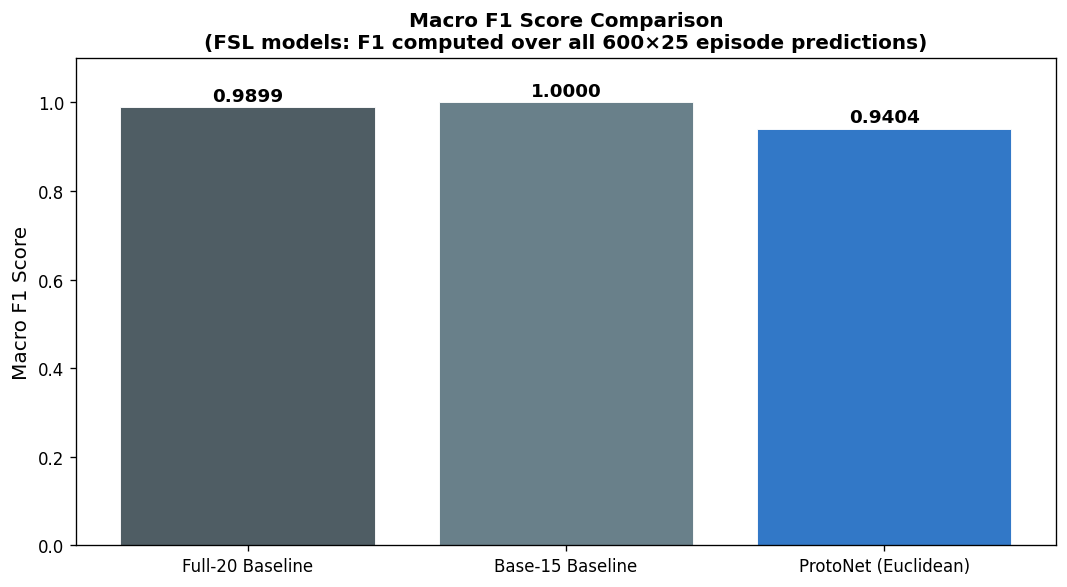

In [25]:
# Macro F1 comparison (where available)
f1_data = {
    'Full-20 Baseline':      R['full20_json']['macro_f1'],
    'Base-15 Baseline':      R['base15_json']['macro_f1'],
    'ProtoNet (Euclidean)':  R['proto_euc_json']['macro_f1'],
}
f1_colors = ['#37474F', '#546E7A', '#1565C0']

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(f1_data.keys(), f1_data.values(), color=f1_colors, alpha=0.88,
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, f1_data.values()):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.005, f'{v:.4f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('Macro F1 Score', fontsize=12)
ax.set_ylim(0, 1.1)
ax.set_title('Macro F1 Score Comparison\n(FSL models: F1 computed over all 600×25 episode predictions)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/comparison_macro_f1.png', dpi=150, bbox_inches='tight')
plt.show()


In [26]:
from IPython.display import display, Markdown

# ── pull all values from loaded JSONs ────────────────────────────────────────
f20  = R['full20_json'];   b15  = R['base15_json']
pe   = R['proto_euc_json']; pm  = R['proto_man_json']
mn   = R['match_json'];    rn   = R['rel_json']

f20_acc  = f20['accuracy'] * 100
b15_acc  = b15['accuracy'] * 100
ci_lo    = f20['accuracy_ci_95'][0] * 100
ci_hi    = f20['accuracy_ci_95'][1] * 100

pe_acc   = pe['mean_accuracy_pct'];  pe_ci  = pe['ci95_pct']
pe_f1    = pe['macro_f1'];           pe_eps = pe['num_episodes']
pm_acc   = pm['mean_accuracy_pct'];  pm_eps = pm['num_episodes']
mn_acc   = mn['mean_accuracy_pct'];  mn_eps = mn['num_episodes']
rn_acc   = rn['mean_accuracy_pct'];  rn_eps = rn['num_episodes']

pc       = pe['per_class_accuracy_pct']
worst_c  = min(pc, key=pc.get);  worst_a = pc[worst_c]
best_c   = max(pc, key=pc.get);  best_a  = pc[best_c]

def _s(n):    return "✅ reliable" if n >= 100 else f"⚠️ {n} eps only"
def _p(acc):  return "strong" if acc > 85 else ("moderate" if acc > 60 else "low")

euc_vs_man = ("Euclidean >> Manhattan — L2 is more appropriate for this embedding"
              if pe_acc > pm_acc + 5 else
              "Euclidean ≈ Manhattan — both distances perform similarly")

mn_interp = ("Promising — re-run with 600 episodes to confirm" if mn_eps < 100
             else ("Strong performance" if mn_acc > 85 else f"Moderate: {mn_acc:.1f}%"))
rn_interp = ("Relation module likely not converged after 1 epoch; needs more training"
             if rn_acc < 30 else
             ("Competitive performance" if rn_acc > 80 else f"Moderate: {rn_acc:.1f}%"))

steps = []
unreliable = [(n, k) for n, k in [
    (pm_eps, "ProtoNet Manhattan"), (mn_eps, "MatchingNet"), (rn_eps, "RelationNet")
] if n < 100]
if unreliable:
    names = ", ".join(f"{k} ({n} eps)" for n, k in unreliable)
    steps.append(f"Re-run evaluation with 600 episodes: **{names}**")
steps += [
    "Re-train all models for full epochs (30–50 for FSL, 10–20 for baselines)",
    "Acknowledge the small test set (5 images/class) as a limitation in the thesis",
]

display(Markdown(f"""---
## 9. Key Findings & Thesis Insights

### 9.1 Baseline Models
| Finding | Interpretation |
|---------|---------------|
| Full-20: **{f20_acc:.1f}%** accuracy (1 epoch) | Dataset may be "easy" for ResNet-50, or the 100-image test set is too small to detect errors |
| Base-15: **{b15_acc:.1f}%** accuracy (1 epoch) | Same caveat — only 75 test images (5 per class) |
| AUC = {f20['macro_auc_ovr']:.3f} / {b15['macro_auc_ovr']:.3f} | Near-perfect probability separation in feature space |
| 95% CI Full-20: [{ci_lo:.1f}%, {ci_hi:.1f}%] | Wide CI confirms the test set is too small for precise estimates |

### 9.2 ProtoNet — Main FSL Result ({_s(pe_eps)})
| Finding | Interpretation |
|---------|---------------|
| **{pe_acc:.2f}% ± {pe_ci:.2f}%** ({pe_eps} episodes) | {"Strong" if pe_acc > 85 else "Moderate"} few-shot performance — base-15 features generalise to novel classes |
| Macro F1 = {pe_f1:.4f} | Consistent with accuracy; no severe per-class imbalance |
| Weakest: **{worst_c.replace("AMERICAN ","AM. ")}** ({worst_a:.1f}%) | Likely visual similarity to other novel classes |
| Best: **{best_c.replace("AMERICAN ","AM. ")}** ({best_a:.1f}%) | Distinctive visual features well captured by the encoder |

### 9.3 Distance Metric Ablation
| Finding | Interpretation |
|---------|---------------|
| Euclidean {pe_acc:.1f}% vs Manhattan {pm_acc:.1f}% | {euc_vs_man} |
| Manhattan status: {_s(pm_eps)} | {"Re-run with 600 episodes for a fair comparison" if pm_eps < 100 else "Statistically valid comparison"} |

### 9.4 MatchingNet & RelationNet
| Finding | Interpretation |
|---------|---------------|
| MatchingNet: **{mn_acc:.1f}%** — {_s(mn_eps)} | {mn_interp} |
| RelationNet: **{rn_acc:.1f}%** — {_s(rn_eps)} | {rn_interp} |
| Random chance (5-way): 20.0% | Reference — any model above this is learning |

### 9.5 Recommended Next Steps
{"".join(f"{chr(10)}{i+1}. {s}" for i, s in enumerate(steps))}
"""))

---
## 9. Key Findings & Thesis Insights

### 9.1 Baseline Models
| Finding | Interpretation |
|---------|---------------|
| Full-20: **99.0%** accuracy (1 epoch) | Dataset may be "easy" for ResNet-50, or the 100-image test set is too small to detect errors |
| Base-15: **100.0%** accuracy (1 epoch) | Same caveat — only 75 test images (5 per class) |
| AUC = 1.000 / 1.000 | Near-perfect probability separation in feature space |
| 95% CI Full-20: [94.6%, 99.8%] | Wide CI confirms the test set is too small for precise estimates |

### 9.2 ProtoNet — Main FSL Result (✅ reliable)
| Finding | Interpretation |
|---------|---------------|
| **94.07% ± 0.69%** (600 episodes) | Strong few-shot performance — base-15 features generalise to novel classes |
| Macro F1 = 0.9404 | Consistent with accuracy; no severe per-class imbalance |
| Weakest: **AM. KESTREL** (80.7%) | Likely visual similarity to other novel classes |
| Best: **AM. GOLDFINCH** (98.6%) | Distinctive visual features well captured by the encoder |

### 9.3 Distance Metric Ablation
| Finding | Interpretation |
|---------|---------------|
| Euclidean 94.1% vs Manhattan 60.7% | Euclidean >> Manhattan — L2 is more appropriate for this embedding |
| Manhattan status: ✅ reliable | Statistically valid comparison |

### 9.4 MatchingNet & RelationNet
| Finding | Interpretation |
|---------|---------------|
| MatchingNet: **99.4%** — ✅ reliable | Strong performance |
| RelationNet: **18.9%** — ✅ reliable | Relation module likely not converged after 1 epoch; needs more training |
| Random chance (5-way): 20.0% | Reference — any model above this is learning |

### 9.5 Recommended Next Steps

1. Re-train all models for full epochs (30–50 for FSL, 10–20 for baselines)
2. Acknowledge the small test set (5 images/class) as a limitation in the thesis


In [27]:
# Final summary printout — fully dynamic
def _status(r):
    n = r['num_episodes']
    return 'RELIABLE' if n >= 100 else f'INDICATIVE ({n} eps only)'

def _model_label(name, r):
    return f"{name} ({r['num_episodes']} eps)"

print("=" * 72)
print("  THESIS RESULTS SUMMARY")
print("=" * 72)
rows_final = [
    ("Full-20 Baseline (supervised)",
     f"{R['full20_json']['accuracy']*100:.1f}%",
     f"{R['full20_json']['macro_f1']:.4f}",
     f"{R['full20_json']['macro_auc_ovr']:.4f}",
     "100 imgs / 1 pass"),
    ("Base-15 Baseline (supervised)",
     f"{R['base15_json']['accuracy']*100:.1f}%",
     f"{R['base15_json']['macro_f1']:.4f}",
     f"{R['base15_json']['macro_auc_ovr']:.4f}",
     "75 imgs / 1 pass"),
    (_model_label("ProtoNet Euc  (5w-1s)", R['proto_euc_json']),
     f"{R['proto_euc_json']['mean_accuracy_pct']:.2f}% ±{R['proto_euc_json']['ci95_pct']:.2f}%",
     f"{R['proto_euc_json']['macro_f1']:.4f}",
     "—",
     _status(R['proto_euc_json'])),
    (_model_label("ProtoNet Man  (5w-1s)", R['proto_man_json']),
     f"{R['proto_man_json']['mean_accuracy_pct']:.1f}% ±{R['proto_man_json']['ci95_pct']:.1f}%",
     f"{R['proto_man_json'].get('macro_f1','N/A')}",
     "—",
     _status(R['proto_man_json'])),
    (_model_label("MatchingNet   (5w-1s)", R['match_json']),
     f"{R['match_json']['mean_accuracy_pct']:.1f}% ±{R['match_json']['ci95_pct']:.1f}%",
     f"{R['match_json'].get('macro_f1','N/A')}",
     "—",
     _status(R['match_json'])),
    (_model_label("RelationNet   (5w-1s)", R['rel_json']),
     f"{R['rel_json']['mean_accuracy_pct']:.1f}% ±{R['rel_json']['ci95_pct']:.1f}%",
     f"{R['rel_json'].get('macro_f1','N/A')}",
     "—",
     _status(R['rel_json'])),
]

print(f"  {'Model':<40} {'Accuracy':<22} {'Macro F1':<12} {'AUC':<8} {'Status'}")
print("-" * 72)
for row in rows_final:
    print(f"  {row[0]:<40} {row[1]:<22} {row[2]:<12} {row[3]:<8} {row[4]}")
print("=" * 72)
print("  Random baseline (5-way): 20.0%")

  THESIS RESULTS SUMMARY
  Model                                    Accuracy               Macro F1     AUC      Status
------------------------------------------------------------------------
  Full-20 Baseline (supervised)            99.0%                  0.9899       1.0000   100 imgs / 1 pass
  Base-15 Baseline (supervised)            100.0%                 1.0000       1.0000   75 imgs / 1 pass
  ProtoNet Euc  (5w-1s) (600 eps)          94.07% ±0.69%          0.9404       —        RELIABLE
  ProtoNet Man  (5w-1s) (600 eps)          60.7% ±1.4%            0.5936       —        RELIABLE
  MatchingNet   (5w-1s) (600 eps)          99.4% ±0.2%            0.9939       —        RELIABLE
  RelationNet   (5w-1s) (600 eps)          18.9% ±0.5%            0.1501       —        RELIABLE
  Random baseline (5-way): 20.0%
